# 05 — Noise, Outlier, Stay-point & tiền khả thi Home/Office

Mục tiêu: lượng hoá các vấn đề cần xử lý trước khi xây model home/office.
1. Outlier tốc độ / gia tốc, các "spike" nhảy toạ độ (A → B xa → A).
2. Mức dao động GPS khi đứng yên (jitter) → căn cứ chọn ngưỡng khoảng cách stay-point.
3. Stay-point detection (Li et al., 2008) + độ nhạy theo tham số (D, T).
4. "Gap stay": thời gian dừng nằm trong khoảng **không ghi** giữa các trajectory.
5. Xem trước khả năng suy ra home (đêm) / office (giờ hành chính) cho từng user.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from numba import njit
from sklearn.cluster import DBSCAN

from utils import add_geo, add_kinematics, haversine, load_points, savefig, setup_style

setup_style()
pts = load_points(["user", "traj_id", "lat", "lon", "ts_utc"])
pts = pts[pts.lat.between(-90, 90)]  # bỏ 1 điểm lat lỗi (xem NB01)
pts = add_geo(pts)
pts = pts[pts.ts_utc.dt.year >= 2007]
n0 = len(pts)
pts = pts.sort_values(["user", "ts_utc"], kind="stable").drop_duplicates(["user", "ts_utc"]).reset_index(drop=True)
print(f"Bỏ {n0 - len(pts):,} điểm trùng timestamp → còn {len(pts):,}")
pts["traj_key"] = pts.user.astype(str) + "_" + pts.traj_id.astype(str)
pts = add_kinematics(pts)

Bỏ 698,900 điểm trùng timestamp → còn 24,178,074


## 1. Outlier tốc độ & gia tốc

In [2]:
v = pts.speed_kmh.dropna()
thr = [100, 200, 300, 500, 1000]
pd.DataFrame({"n": [(v > t).sum() for t in thr], "%": [(v > t).mean() * 100 for t in thr]}, index=[f"> {t} km/h" for t in thr])

,n,%
> 100 km/h,1305501,5.4037
> 200 km/h,88554,0.3665
> 300 km/h,53453,0.2213
> 500 km/h,49103,0.2032
> 1000 km/h,1749,0.0072


In [3]:
pts["acc"] = pts.groupby("traj_key", observed=True).speed_kmh.diff() / 3.6 / pts.dt_s
a = pts.acc.abs().dropna()
print(a.describe(percentiles=[.5, .9, .99, .999]))
print(f"% điểm |gia tốc| > 5 m/s²: {(a > 5).mean():.3%}  | > 10 m/s²: {(a > 10).mean():.3%}")

count   24,140,736.0000
mean             4.2412
std          1,263.6676
min              0.0000
50%              0.1817
90%              0.8826
99%              3.5987
99.9%           17.3099
max        861,504.9536
Name: acc, dtype: float64
% điểm |gia tốc| > 5 m/s²: 0.644%  | > 10 m/s²: 0.242%


In [4]:
# Spike A→B→A: tốc độ vào & ra đều rất lớn nhưng điểm trước và sau lại gần nhau
k = pts.traj_key.to_numpy()
same_prev = np.r_[False, k[1:] == k[:-1]]
same_next = np.r_[k[1:] == k[:-1], False]
v_in = pts.speed_kmh.to_numpy()
v_out = np.r_[v_in[1:], np.nan]
lat, lon = pts.lat.to_numpy(), pts.lon.to_numpy()
d_skip = np.r_[np.nan, haversine(lat[:-2], lon[:-2], lat[2:], lon[2:]), np.nan]
d_in = pts.dist_m.to_numpy()
spike = same_prev & same_next & (v_in > 150) & (v_out > 150) & (d_skip < 0.3 * d_in)
pts["spike"] = spike
print(f"Spike A→B→A: {spike.sum():,} điểm, ở {pts.loc[spike, 'traj_key'].nunique():,} trajectory, {pts.loc[spike, 'user'].nunique()} user")
print("Khoảng nhảy (km) của spike:")
print((pts.loc[spike, "dist_m"] / 1000).describe(percentiles=[.5, .9, .99]))

Spike A→B→A: 710 điểm, ở 109 trajectory, 48 user
Khoảng nhảy (km) của spike:
count   710.0000
mean    711.8898
std     316.6724
min       0.0432
50%     856.6820
90%     861.6821
99%     861.9859
max     862.0038
Name: dist_m, dtype: float64


In [5]:
# Spike nhảy tới đâu? Nếu nhiều spike rơi vào cùng 1 toạ độ → toạ độ "mặc định" của thiết bị/firmware, không phải nhiễu ngẫu nhiên
sp = pts.loc[spike]
print(sp.assign(lat_r=sp.lat.round(2), lon_r=sp.lon.round(2)).groupby(["lat_r", "lon_r"])
      .agg(n=("user", "size"), users=("user", "nunique"), first=("ts_utc", "min"), last=("ts_utc", "max"))
      .sort_values("n", ascending=False).head(10))

                   n  users               first                last
lat_r   lon_r                                                      
40.0100 116.3200  12      7 2008-06-19 23:52:28 2009-07-11 07:38:01
39.7800 116.1800  11      1 2008-09-26 09:18:08 2008-09-26 09:18:58
34.2900 109.0000  10      1 2008-09-26 09:32:31 2008-09-26 09:33:16
39.7900 116.1900  10      1 2008-09-26 09:17:13 2008-09-26 09:17:58
39.8100 116.1700  10      1 2008-09-26 09:15:13 2008-09-26 09:15:58
34.3400 109.1100  10      1 2008-09-26 09:24:21 2008-09-26 09:25:06
34.2900 108.9900  10      1 2008-09-26 09:33:22 2008-09-26 09:34:08
34.3200 109.0800   9      1 2008-09-26 09:26:41 2008-09-26 09:27:21
39.8200 116.1600   9      1 2008-09-26 09:14:23 2008-09-26 09:15:03
34.3000 109.0200   9      1 2008-09-26 09:30:56 2008-09-26 09:31:36


**Insight:** phần lớn spike (~860 km) đến từ **1 trajectory ngày 2008-09-26**, toạ độ nhảy qua lại liên tục giữa Bắc Kinh (39.8N 116.2E)
và Tây An (34.3N 109.0E) mỗi vài giây → giống 2 luồng vị trí bị trộn (2 thiết bị / file ghép), không phải nhiễu ngẫu nhiên.
Loại lỗi này cần phát hiện ở mức **trajectory** (tỉ lệ spike cao → loại cả file), không chỉ ở mức điểm.

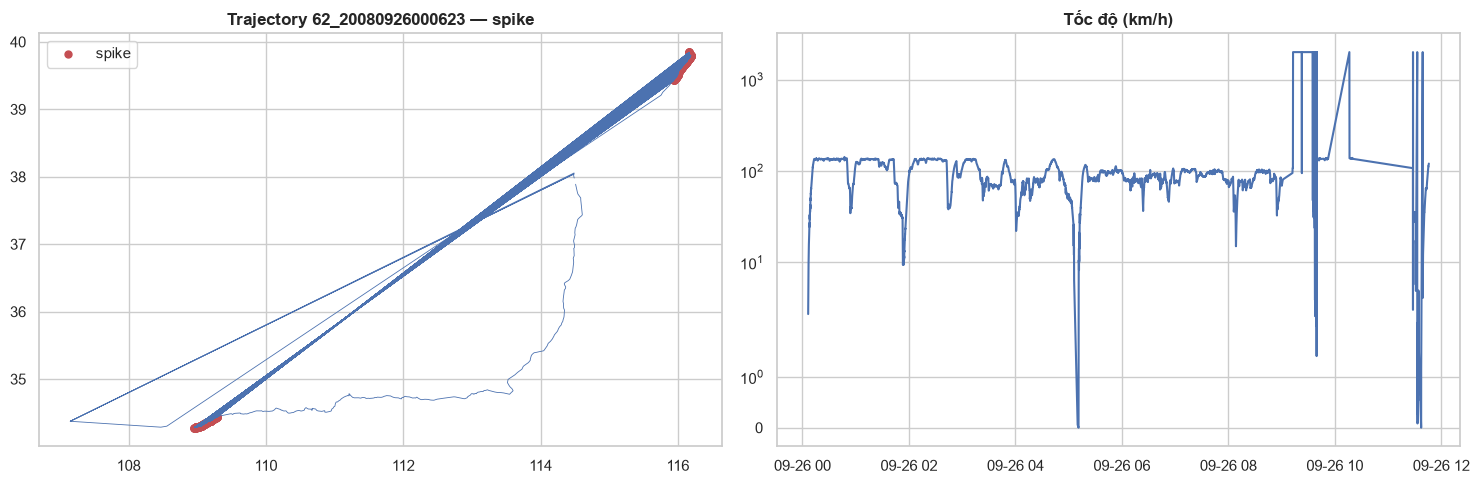

In [6]:
# Ví dụ 1 trajectory có spike lớn
ex = pts.loc[spike].sort_values("dist_m", ascending=False).traj_key.iloc[0]
g = pts[pts.traj_key == ex]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(g.lon, g.lat, "-", lw=0.6); ax[0].scatter(g.loc[g.spike, "lon"], g.loc[g.spike, "lat"], c="r", s=25, label="spike")
ax[0].legend(); ax[0].set_title(f"Trajectory {ex} — spike")
ax[1].plot(g.ts_utc, g.speed_kmh.clip(upper=2000)); ax[1].set_yscale("symlog"); ax[1].set_title("Tốc độ (km/h)")
plt.tight_layout(); savefig("05_spike_example"); plt.show()

**Insight:** outlier tốc độ ít về tỉ lệ nhưng biên độ cực lớn (nhảy hàng chục – hàng trăm km), làm sai quãng đường và có thể
tạo stay-point giả. Lọc theo tốc độ đơn thuần sẽ xoá nhầm điểm hợp lệ *sau* spike → nên dùng kiểm tra **A→B→A** (hoặc median filter) rồi
tính lại tốc độ; ngưỡng tốc độ ngoài máy bay ~ 300–400 km/h.

## 2. Jitter khi đứng yên
Lấy các cửa sổ 10 phút mà quãng đường tổng < 100 m liên tục... đơn giản hơn: các đoạn có tốc độ trung vị < 1 km/h, đo bán kính phân tán.

13,236 cửa sổ 10' đứng yên
              p50         p90          mx
count 13,236.0000 13,236.0000 13,236.0000
mean       8.8756     46.0993     70.0888
std       24.3049    147.1716    206.0898
min        0.0000      0.0000      0.0000
50%        4.8069     16.2791     24.4000
75%        9.4026     32.0231     46.4327
90%       16.4470     71.3264    112.6444
95%       24.5461    148.8777    258.8245
99%       79.3282    745.9422  1,080.0416
max      840.1293  4,367.1537  5,387.6950


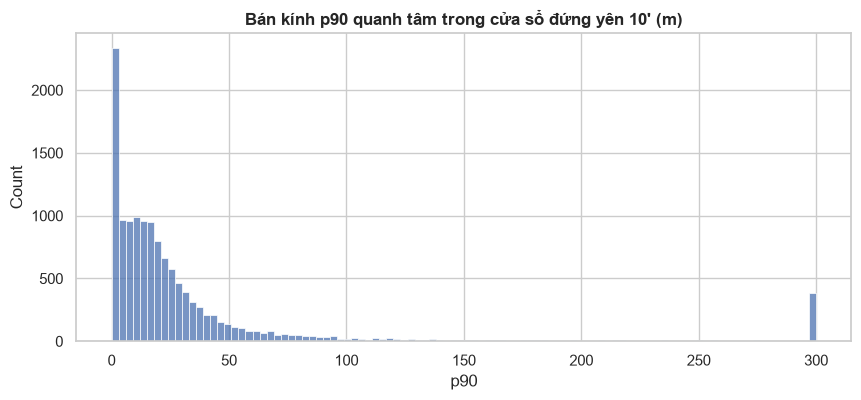

In [7]:
pts["win"] = pts.ts_utc.dt.floor("10min")
w = pts[pts.dt_s <= 10].groupby(["traj_key", "win"], observed=True).agg(
    n=("lat", "size"), v_med=("speed_kmh", "median"), lat_c=("lat", "median"), lon_c=("lon", "median"))
w = w[(w.n >= 30) & (w.v_med < 1)]
tmp = pts.join(w[["lat_c", "lon_c"]], on=["traj_key", "win"], how="inner")
tmp["r"] = haversine(tmp.lat, tmp.lon, tmp.lat_c, tmp.lon_c)
jit = tmp.groupby(["traj_key", "win"], observed=True).r.agg(p50="median", p90=lambda s: s.quantile(.9), mx="max")
print(f"{len(jit):,} cửa sổ 10' đứng yên")
print(jit.describe(percentiles=[.5, .75, .9, .95, .99]))
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(jit.p90.clip(upper=300), bins=100, ax=ax); ax.set_title("Bán kính p90 quanh tâm trong cửa sổ đứng yên 10' (m)")
savefig("05_jitter"); plt.show()

**Insight:** khi đứng yên, phần lớn điểm nằm trong vài chục mét quanh tâm, nhưng đuôi dài (indoor/multipath → hàng trăm m).
→ ngưỡng khoảng cách stay-point **~200 m** là hợp lý (đủ bao jitter p90–p95), 50–100 m sẽ chẻ 1 lần dừng thành nhiều mảnh.

## 3. Stay-point detection (Li et al. 2008) trên chuỗi điểm theo user
Chạy trên **toàn bộ chuỗi của user (gộp mọi trajectory theo thời gian)** để bắt được cả "gap stay":
điểm cuối trajectory trước và điểm đầu trajectory sau gần nhau ⇒ user ở yên trong khoảng không ghi.

In [8]:
@njit(cache=True)
def _hav(la1, lo1, la2, lo2):
    r = np.pi / 180
    a = np.sin((la2 - la1) * r / 2) ** 2 + np.cos(la1 * r) * np.cos(la2 * r) * np.sin((lo2 - lo1) * r / 2) ** 2
    return 2 * 6371008.8 * np.arcsin(np.sqrt(a))


@njit(cache=True)
def stay_points(lat, lon, t, D, T):
    n = len(lat)
    out = []
    i = 0
    while i < n:
        j = i + 1
        while j < n and _hav(lat[i], lon[i], lat[j], lon[j]) <= D:
            j += 1
        if t[j - 1] - t[i] >= T:
            out.append((i, j - 1))
            i = j
        else:
            i += 1
    return out


def detect(df, D=200, T=20 * 60, max_gap_h=48):
    users, starts, ends = [], [], []
    for u, idx in df.groupby("user").indices.items():
        g = df.iloc[idx]
        t = g.ts_utc.to_numpy().astype("datetime64[s]").astype(np.int64).astype(np.float64)
        for i, j in stay_points(g.lat.to_numpy(), g.lon.to_numpy(), t, D, T):
            users.append(u); starts.append(idx[i]); ends.append(idx[j])
    s = pd.DataFrame({"user": users, "i0": starts, "i1": ends})
    cs = np.r_[0, np.cumsum(df.lat.to_numpy())]; cl = np.r_[0, np.cumsum(df.lon.to_numpy())]
    cnt = s.i1 - s.i0 + 1
    s["lat"] = (cs[s.i1 + 1] - cs[s.i0]) / cnt
    s["lon"] = (cl[s.i1 + 1] - cl[s.i0]) / cnt
    s["n_points"] = cnt
    s["start_utc"] = df.ts_utc.to_numpy()[s.i0]; s["end_utc"] = df.ts_utc.to_numpy()[s.i1]
    s["dur_h"] = (s.end_utc - s.start_utc).dt.total_seconds() / 3600
    tk = df.traj_key.to_numpy()
    s["cross_traj"] = tk[s.i0] != tk[s.i1]  # stay kéo qua khoảng không ghi giữa 2 file
    # khoảng trống lớn nhất bên trong stay
    dtu = np.r_[0, np.diff(df.ts_utc.to_numpy().astype("datetime64[s]").astype(np.int64))].astype(float)
    s["max_gap_h"] = [dtu[a + 1:b + 1].max() / 3600 if b > a else 0 for a, b in zip(s.i0, s.i1)]
    s["offset_h"] = df.utc_offset_h.fillna(8).to_numpy()[s.i0]
    s["start_local"] = s.start_utc + pd.to_timedelta(s.offset_h, unit="h")
    s["end_local"] = s.end_utc + pd.to_timedelta(s.offset_h, unit="h")
    s = s[s.max_gap_h <= max_gap_h]  # bỏ stay nối qua các khoảng trống quá dài (không đáng tin)
    return s.reset_index(drop=True)


import time
t0 = time.time()
stays = detect(pts, D=200, T=20 * 60)
print(f"{len(stays):,} stay-points trong {time.time() - t0:.1f}s, {stays.user.nunique()} user")
stays[["n_points", "dur_h", "max_gap_h"]].describe(percentiles=[.25, .5, .75, .9, .99])

23,944 stay-points trong 8.5s, 177 user


,n_points,dur_h,max_gap_h
count,"23,944.0000","23,944.0000","23,944.0000"
mean,220.8335,4.2551,3.8713
std,464.4165,6.4065,6.3262
min,2.0000,0.3333,0.0006
25%,48.0000,0.5356,0.2283
50%,103.0000,1.2335,0.7911
75%,237.0000,5.6154,5.0460
90%,469.0000,12.4522,12.1966
99%,"1,802.1400",34.4953,33.8927
max,"16,973.0000",105.0736,47.8942


% stay kéo qua 2+ trajectory (gap stay): 30.0%
% tổng thời gian stay thuộc gap stay: 77.9%


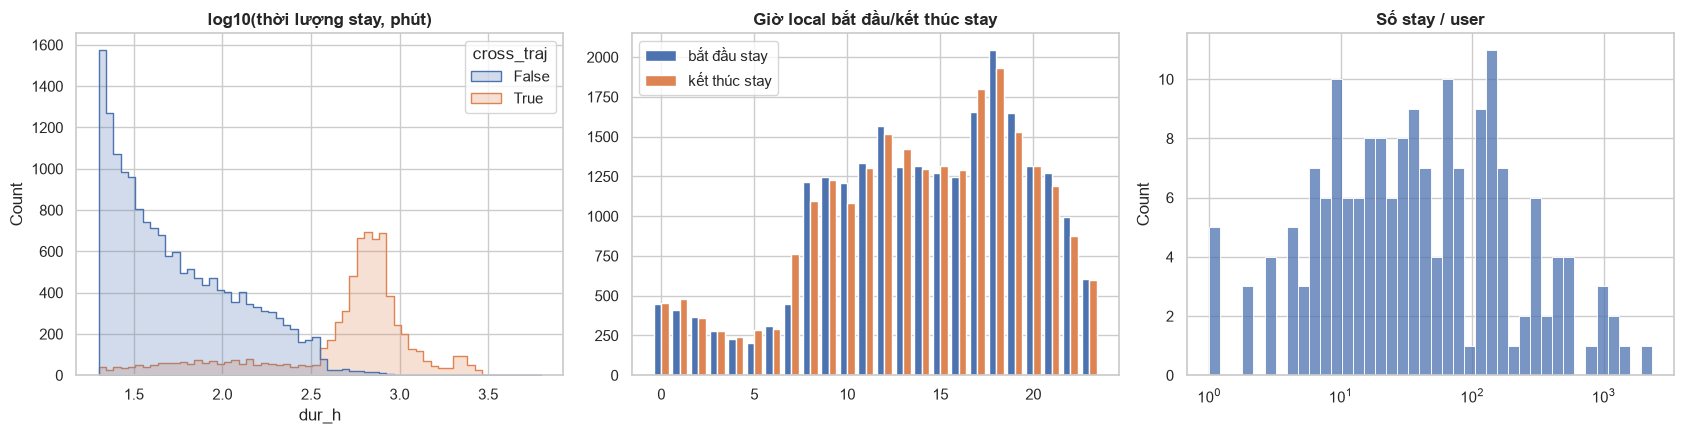

In [9]:
print(f"% stay kéo qua 2+ trajectory (gap stay): {stays.cross_traj.mean():.1%}")
print(f"% tổng thời gian stay thuộc gap stay: {stays.loc[stays.cross_traj, 'dur_h'].sum() / stays.dur_h.sum():.1%}")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(data=stays, x=np.log10(stays.dur_h * 60), hue="cross_traj", bins=60, ax=axes[0], element="step")
axes[0].set_title("log10(thời lượng stay, phút)")
sh = stays.start_local.dt.hour.value_counts().sort_index(); eh = stays.end_local.dt.hour.value_counts().sort_index()
axes[1].bar(sh.index - .2, sh.values, width=.4, label="bắt đầu stay"); axes[1].bar(eh.index + .2, eh.values, width=.4, label="kết thúc stay")
axes[1].legend(); axes[1].set_title("Giờ local bắt đầu/kết thúc stay")
sns.histplot(stays.groupby("user").size(), bins=40, log_scale=True, ax=axes[2]); axes[2].set_title("Số stay / user")
plt.tight_layout(); savefig("05_stay_stats"); plt.show()

### 3.1 Độ nhạy tham số (D, T)

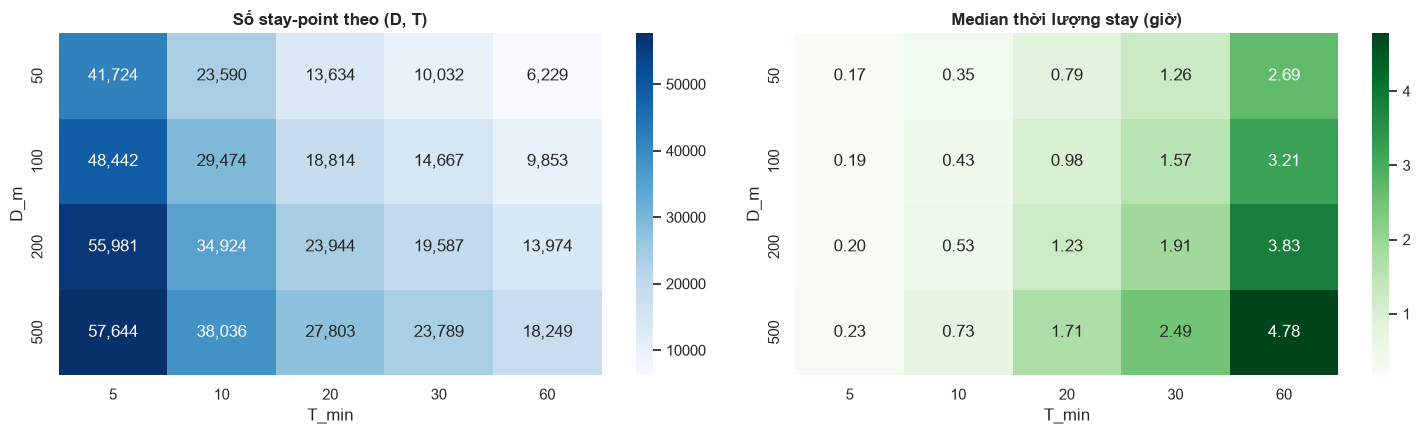

,D_m,T_min,n_stays,users,median_dur_h,pct_cross_traj,stays_per_user_med
0,50,5,41724,178,0.1708,6.5885,61.5000
1,50,10,23590,175,0.3539,11.5176,33.0000
2,50,20,13634,166,0.7883,19.4660,19.0000
3,50,30,10032,160,1.2612,25.7476,16.0000
4,50,60,6229,154,2.6883,38.2084,10.0000
5,100,5,48442,181,0.1903,9.8716,67.0000
6,100,10,29474,178,0.4306,16.1329,41.5000
7,100,20,18814,175,0.9818,24.8485,26.0000
8,100,30,14667,171,1.5681,31.0902,21.0000
9,100,60,9853,167,3.2064,43.4081,14.0000


In [10]:
rows = []
for D in [50, 100, 200, 500]:
    for T in [5, 10, 20, 30, 60]:
        s = detect(pts, D=D, T=T * 60)
        rows.append({"D_m": D, "T_min": T, "n_stays": len(s), "users": s.user.nunique(),
                     "median_dur_h": s.dur_h.median(), "pct_cross_traj": s.cross_traj.mean() * 100,
                     "stays_per_user_med": s.groupby("user").size().median()})
sens = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(sens.pivot(index="D_m", columns="T_min", values="n_stays"), annot=True, fmt=",.0f", cmap="Blues", ax=ax[0])
ax[0].set_title("Số stay-point theo (D, T)")
sns.heatmap(sens.pivot(index="D_m", columns="T_min", values="median_dur_h"), annot=True, fmt=".2f", cmap="Greens", ax=ax[1])
ax[1].set_title("Median thời lượng stay (giờ)")
plt.tight_layout(); savefig("05_stay_sensitivity"); plt.show()
sens

## 4. Xem trước Home / Office
Ý tưởng: gom stay theo vị trí (DBSCAN haversine, eps = 200 m) → mỗi cụm là 1 "địa điểm".
- **Home candidate**: cụm có nhiều giờ stay nhất trong cửa sổ đêm 22–06h.
- **Office candidate**: cụm (khác home) có nhiều giờ stay nhất trong T2–T6 9–18h.
Đây chỉ là kiểm tra khả thi cho EDA, không phải model.

In [11]:
def hours_in_windows(s: pd.DataFrame) -> pd.DataFrame:
    """Tách stay thành các giờ local để đếm giờ đêm / giờ hành chính."""
    rec = []
    for r in s[["start_local", "end_local"]].itertuples():
        hrs = pd.date_range(r.start_local.floor("h"), r.end_local, freq="h")
        for h in hrs:
            a = max(h, r.start_local); b = min(h + pd.Timedelta(hours=1), r.end_local)
            rec.append((r.Index, h, (b - a).total_seconds() / 3600))
    x = pd.DataFrame(rec, columns=["sid", "hour_ts", "hrs"])
    hr, dw = x.hour_ts.dt.hour, x.hour_ts.dt.day_of_week
    x["night"] = (hr >= 22) | (hr < 6)
    x["work"] = (dw < 5) & hr.between(9, 17)
    x["night_date"] = (x.hour_ts - pd.Timedelta(hours=6)).dt.normalize()
    return x

hw = hours_in_windows(stays)
agg = hw.groupby("sid").apply(lambda g: pd.Series({"night_h": g.loc[g.night, "hrs"].sum(),
                                                    "work_h": g.loc[g.work, "hrs"].sum()}))
stays = stays.join(agg)

In [12]:
labels_all = np.full(len(stays), -1)
for u, idx in stays.groupby("user").indices.items():
    X = np.radians(stays.iloc[idx][["lat", "lon"]].to_numpy())
    lab = DBSCAN(eps=200 / 6371008.8, min_samples=1, metric="haversine", algorithm="ball_tree").fit_predict(X)
    labels_all[idx] = lab
stays["place"] = labels_all

place = (stays.groupby(["user", "place"])
         .agg(lat=("lat", "mean"), lon=("lon", "mean"), visits=("dur_h", "size"), total_h=("dur_h", "sum"),
              night_h=("night_h", "sum"), work_h=("work_h", "sum")).reset_index())
nights = hw[hw.night].merge(stays[["user", "place"]], left_on="sid", right_index=True)
place = place.merge(nights.groupby(["user", "place"]).night_date.nunique().rename("n_nights"),
                    on=["user", "place"], how="left").fillna({"n_nights": 0})

home = place.sort_values("night_h", ascending=False).groupby("user").head(1).set_index("user")
office = (place.merge(home[["place"]].rename(columns={"place": "home_place"}), left_on="user", right_index=True)
          .query("place != home_place").sort_values("work_h", ascending=False).groupby("user").head(1).set_index("user"))
user_night_total = place.groupby("user").night_h.sum()
user_work_total = place.groupby("user").work_h.sum()
ho = pd.DataFrame({
    "home_night_h": home.night_h, "home_n_nights": home.n_nights,
    "home_share_night": home.night_h / user_night_total,
    "office_work_h": office.work_h, "office_share_work": office.work_h / user_work_total,
    "home_office_km": haversine(home.lat, home.lon, office.lat.reindex(home.index), office.lon.reindex(home.index)) / 1000,
})
print(ho.describe(percentiles=[.25, .5, .75]))
crit = pd.Series({
    "User có stay": stays.user.nunique(),
    "Có home candidate (>= 3 đêm)": (ho.home_n_nights >= 3).sum(),
    "Home chiếm >= 50% giờ đêm": ((ho.home_n_nights >= 3) & (ho.home_share_night >= .5)).sum(),
    "Có office candidate (>= 10h giờ HC)": (ho.office_work_h >= 10).sum(),
    "Có cả home (>=3 đêm) & office (>=10h)": ((ho.home_n_nights >= 3) & (ho.office_work_h >= 10)).sum(),
})
crit.to_frame("số user")

       home_night_h  home_n_nights  home_share_night  office_work_h  office_share_work  home_office_km
count      177.0000       177.0000          168.0000       171.0000           163.0000        171.0000
mean       129.8016        19.9209            0.6857        60.2602             0.4728        144.1453
std        348.0674        48.7078            0.2249       146.9170             0.3276        647.7694
min          0.0000         0.0000            0.1957         0.0000             0.0000          0.2017
25%          8.0000         1.0000            0.5052         2.4897             0.1566          2.3881
50%         30.0714         5.0000            0.6826        11.4736             0.4811          6.7814
75%         94.0447        18.0000            0.8830        52.6488             0.7310         17.4645
max      2,907.2144       388.0000            1.0000     1,188.5297             1.0000      7,514.7710


,số user
User có stay,177
Có home candidate (>= 3 đêm),111
Home chiếm >= 50% giờ đêm,87
Có office candidate (>= 10h giờ HC),91
Có cả home (>=3 đêm) & office (>=10h),84


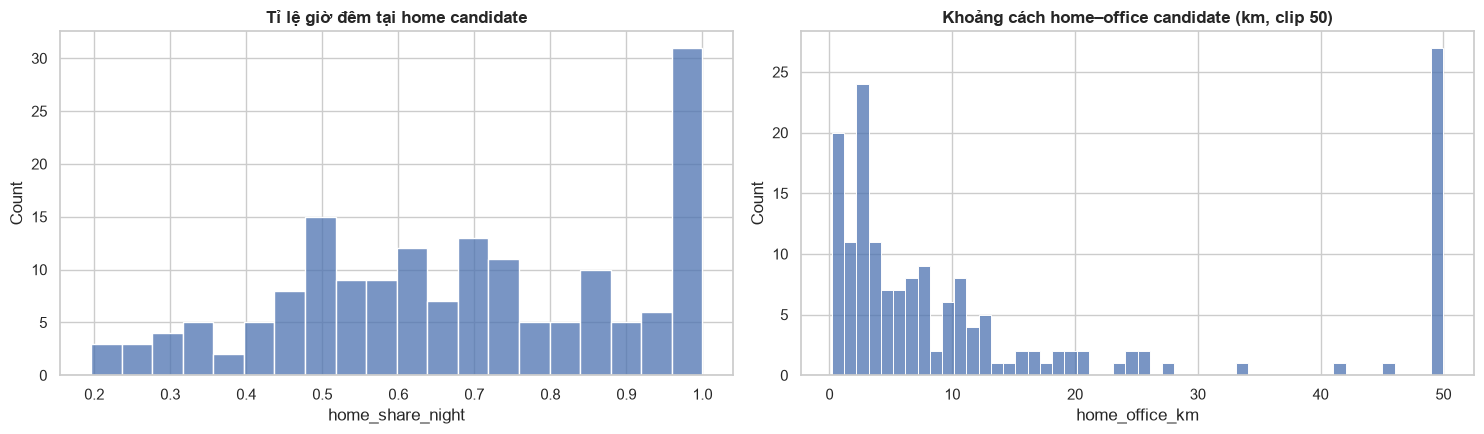

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(ho.home_share_night.dropna(), bins=20, ax=ax[0]); ax[0].set_title("Tỉ lệ giờ đêm tại home candidate")
sns.histplot(ho.home_office_km.dropna().clip(upper=50), bins=50, ax=ax[1]); ax[1].set_title("Khoảng cách home–office candidate (km, clip 50)")
plt.tight_layout(); savefig("05_home_office_preview"); plt.show()

In [14]:
# Office candidate có tập trung ở cùng chỗ giữa các user không? (MSRA / đại học ở Haidian)
oc = office[office.work_h >= 10]
oc_cell = oc.assign(c_lat=(oc.lat / 0.005).round() * 0.005, c_lon=(oc.lon / 0.005).round() * 0.005).groupby(["c_lat", "c_lon"]).size()
print("Top ô ~500m chứa nhiều office candidate nhất:")
print(oc_cell.sort_values(ascending=False).head(5))
hc = home[home.n_nights >= 3]
hc_cell = hc.assign(c_lat=(hc.lat / 0.005).round() * 0.005, c_lon=(hc.lon / 0.005).round() * 0.005).groupby(["c_lat", "c_lon"]).size()
print("Top ô ~500m chứa nhiều home candidate nhất:")
print(hc_cell.sort_values(ascending=False).head(5))

Top ô ~500m chứa nhiều office candidate nhất:
c_lat    c_lon   
39.9750  116.3300    26
39.9800  116.3050     6
39.9750  116.3350     6
40.0100  116.4800     3
39.9350  116.3500     2
dtype: int64
Top ô ~500m chứa nhiều home candidate nhất:
c_lat    c_lon   
39.9750  116.3300    15
39.9800  116.3300     9
39.9750  116.3400     4
40.0050  116.3250     4
39.9700  116.3050     3
dtype: int64


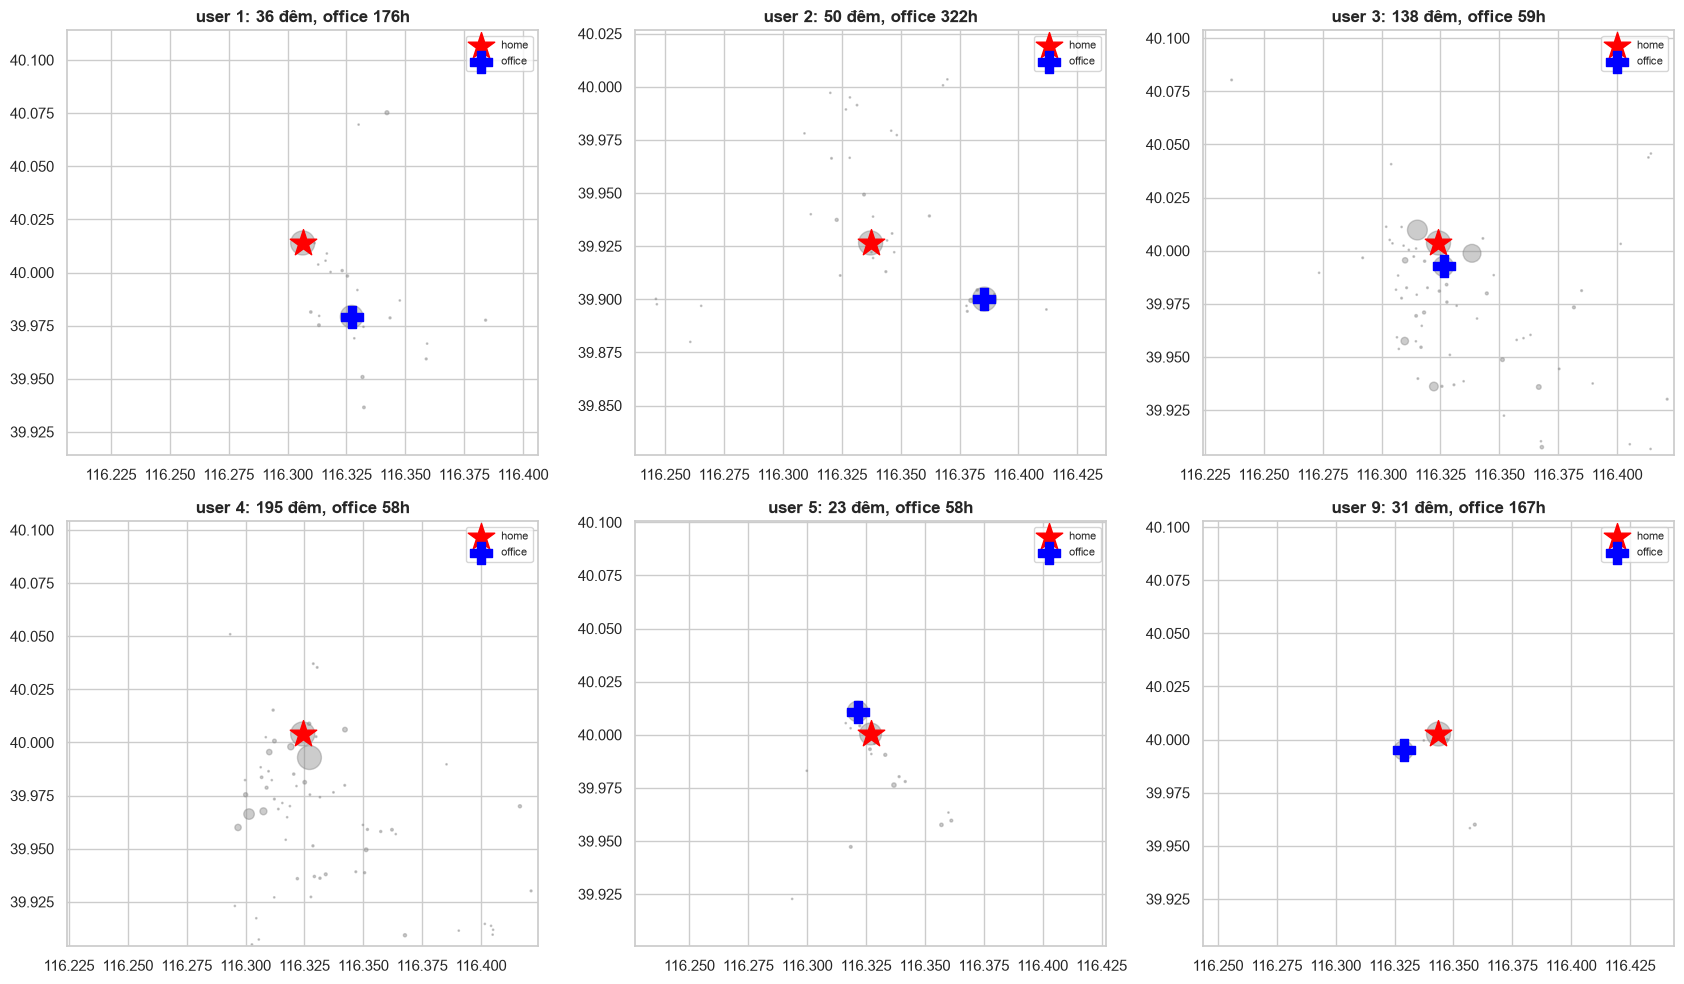

In [15]:
# Vẽ vài user mẫu: toàn bộ stay (kích thước ~ giờ), đánh dấu home/office
sample_users = ho[(ho.home_n_nights >= 10) & (ho.office_work_h >= 20)].index[:6]
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, u in zip(axes.ravel(), sample_users):
    p = place[place.user == u]
    ax.scatter(p.lon, p.lat, s=np.clip(p.total_h, 1, 300), alpha=.4, c="gray")
    ax.scatter(home.loc[u, "lon"], home.loc[u, "lat"], marker="*", s=400, c="red", label="home")
    if u in office.index:
        ax.scatter(office.loc[u, "lon"], office.loc[u, "lat"], marker="P", s=250, c="blue", label="office")
    ax.set_title(f"user {u}: {ho.loc[u, 'home_n_nights']:.0f} đêm, office {ho.loc[u, 'office_work_h']:.0f}h")
    ax.legend(fontsize=8)
    hl, hn = home.loc[u, "lat"], home.loc[u, "lon"]  # zoom ±0.1° (~10 km) quanh home
    ax.set_xlim(hn - .1, hn + .1); ax.set_ylim(hl - .1, hl + .1)
plt.tight_layout(); savefig("05_sample_users_home_office"); plt.show()

### 4.1 Home có ổn định theo thời gian? (user nhiều dữ liệu)

In [16]:
long_users = stays.groupby("user").start_local.agg(lambda s: (s.max() - s.min()).days).sort_values(ascending=False).head(8).index
nh = nights[nights.user.isin(long_users)].copy()
nh["quarter"] = nh.night_date.dt.to_period("Q")
q = (nh.groupby(["user", "quarter", "place"]).hrs.sum().reset_index()
     .sort_values("hrs", ascending=False).groupby(["user", "quarter"]).head(1))
stab = q.groupby("user").agg(n_quarters=("quarter", "nunique"), n_distinct_home=("place", "nunique"))
stab

,n_quarters,n_distinct_home
user,,
55,2,2
58,3,3
111,3,3
128,14,3
140,6,2
142,8,4
153,18,3
163,18,7


**Insight tổng hợp NB05:**
- Phần lớn thời gian stay (đặc biệt ban đêm) nằm trong **gap stay** giữa 2 trajectory → nếu chỉ chạy stay-point bên trong từng file
  sẽ gần như không thấy "nhà". Pipeline nên chạy trên chuỗi điểm của user theo thời gian và có giới hạn độ dài gap.
- Số stay rất nhạy với T (5' vs 30'), ít nhạy hơn với D trong khoảng 100–500m → chọn D ≈ 200m, T ≈ 20–30' là điểm cân bằng; ghi rõ giả định.
- Chỉ một phần user có đủ đêm/giờ hành chính để suy luận home/office tin cậy → cần **confidence** (số đêm hỗ trợ, tỉ lệ giờ đêm tại cụm)
  và trả về "không đủ dữ liệu" thay vì đoán.
- Office candidate của nhiều user dồn vào vài ô ở Haidian → có thể dùng làm sanity check thủ công.
- User dữ liệu dài có thể **đổi nhà** theo quý → nên tính theo cửa sổ thời gian.
- Một số office candidate nằm ở thành phố khác (công tác/du lịch, vd. home–office > 100 km) → nên giới hạn office trong bán kính hợp lý quanh home
  hoặc yêu cầu lặp lại qua nhiều tuần.
- Ô (39.975N, 116.33E) vừa là office vừa là home của nhiều user → nhiều người là sinh viên/nhân viên ở ký túc xá/campus: home ≈ office là trường hợp thật, không hẳn lỗi.